In [1]:
import json
import sys

import cv2
import numpy as np
import matplotlib.pyplot as plt

sys.path.append('..')
from fisheye_camera import CameraCalibrationParameters
from detection_area import CameraConfiguration, DetectionArea

%load_ext autoreload
%autoreload 2

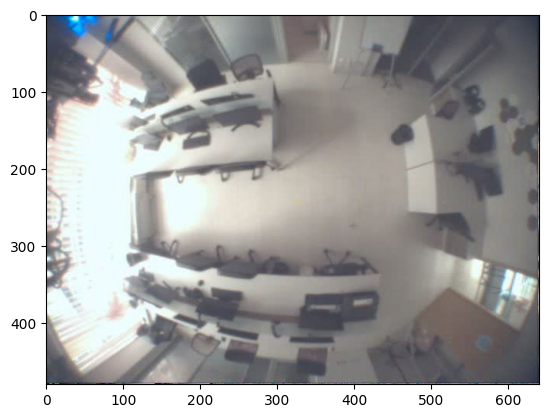

In [2]:
img = cv2.cvtColor(cv2.imread('example.jpg'), cv2.COLOR_BGR2RGB)
plt.imshow(img)

cam3 width = 821.0, height = 477.0
cam4 width = 1880.0, height = 587.0
cam4 with limit width = 1266.0, height = 395.0


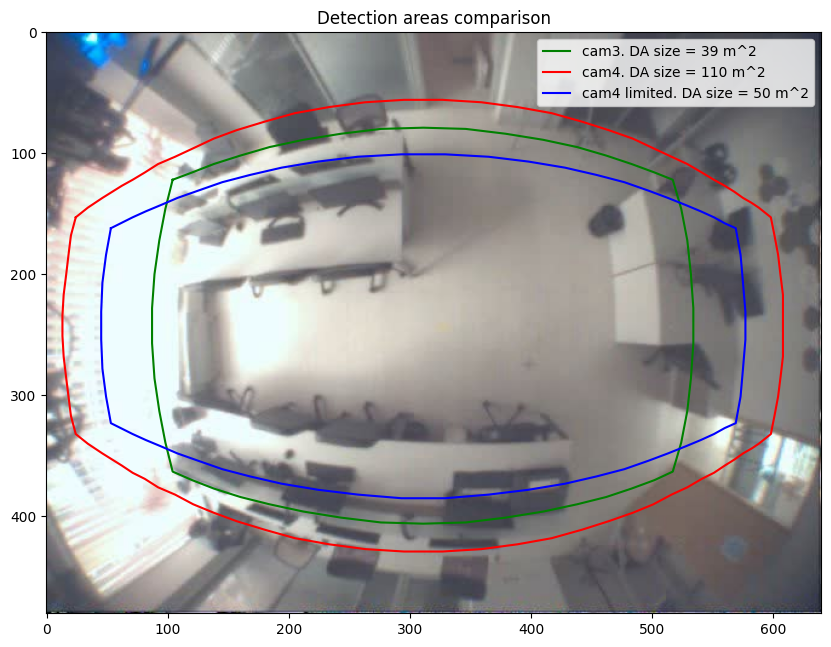

In [8]:
plt.figure(figsize=(10, 10))

H = 270

with open("../camera_calibration/params/pg2-video_20241119142311.json", "rt") as f:
    data = json.load(f)

calibration_params = CameraCalibrationParameters(
    data["LENS_PARAMS"]["CX"],
    data["LENS_PARAMS"]["CY"],
    data["LENS_PARAMS"]["FX"],
    data["LENS_PARAMS"]["FY"],
    data["LENS_PARAMS"]["K0"],
    data["LENS_PARAMS"]["K1"],
    data["LENS_PARAMS"]["K2"],
    data["LENS_PARAMS"]["K3"],
)

cam_config = CameraConfiguration(
    calibration_params,
    135,
    109,
    H,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())
print(f"cam3 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")
 
plt.imshow(img)
plt.plot(poly[:, 0], poly[:, 1], 'g-', label=f"cam3. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")

cam_config = CameraConfiguration(
    calibration_params,
    data["LENS_PARAMS"]["FOV_X"],
    data["LENS_PARAMS"]["FOV_Y"],
    H,
    data["IMG_W"],
    data["IMG_H"]
)

da_cam3 = DetectionArea(cam_config)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'r-', label=f"cam4. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

da_cam3 = DetectionArea(cam_config, True)

poly = np.array(da_cam3.polygon_in_pixels())

plt.plot(poly[:, 0], poly[:, 1], 'b-', label=f"cam4 limited. DA size = {round(da_cam3.m_rectangle_cm.h * da_cam3.m_rectangle_cm.w / 10000)} m^2")
print(f"cam4 with limit width = {da_cam3.m_rectangle_cm.w}, height = {da_cam3.m_rectangle_cm.h}")

plt.ylim(480, 0)

plt.title("Detection areas comparison")
plt.legend()